# Simulation: waste, shortage and cost of the order quantities

CRISP-DM phase 5, research question 3: **does ordering at the right quantile reduce the cost of waste and
shortage compared with ordering the normal (point) forecast?**

For every test week the kitchen orders $q$ portions and the real demand is $y$:

$$C = c_o \sum \max(q - y, 0) + c_u \sum \max(y - q, 0)$$

- $c_o$ = cost of one wasted portion (over-ordering), fixed at 1
- $c_u$ = cost of one missing portion (under-ordering: lost sale, unhappy customer)
- the cost ratio $r = c_u / c_o$ is tested at 0.5, 1, 1.5, 2, 3, 4 and 5, because the real costs are not in the dataset

Newsvendor rule: the cheapest order is the quantile $\tau^* = c_u / (c_u + c_o) = r / (r + 1)$ of demand.
So for each $r$ we order the quantile forecast at $\tau^*$. When $\tau^*$ is between two of our levels
(e.g. 0.75 is between 0.7 and 0.8) we take the value half way between them (`src/simulation.py`).

$\tau^*$ comes from the formula, it is **not** chosen by looking at the test weeks, so there is no leakage.

Order policies compared (same 3 folds x 10 test weeks as before):
- **Point Linear Regression** and **Point LightGBM**: order the normal forecast, whatever the cost ratio
- **Linear QR**, **Quantile XGBoost**, **Quantile LightGBM**: order the forecast at $\tau^*$

Orders are rounded to whole portions.

In [1]:
import sys
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.folds import ORIGINS
from src.metrics import diebold_mariano
from src.simulation import TAUS, COST_RATIOS, critical_ratio, quantity_at_tau, simulate
from src.plot_settings import set_ieee_style, save_fig, ONE_COL, TWO_COL

set_ieee_style()
pd.set_option('display.max_columns', 30)

## 1. Load the forecasts from notebooks 04, 05 and 06

In [2]:
keys = ['series_id', 'week', 'origin']
quantiles = pd.read_parquet('../data/processed/predictions_quantiles.parquet')
trees = pd.read_parquet('../data/processed/predictions_trees.parquet')[keys + ['LightGBM']]
baselines = pd.read_parquet('../data/processed/predictions_baselines.parquet')[keys + ['Linear Regression']]

preds = quantiles.merge(trees, on=keys).merge(baselines, on=keys)
print(len(quantiles), len(preds))      # same rows, nothing lost in the merge

98475 98475


In [3]:
# the quantile level to order at, for every cost ratio
pd.DataFrame({'cost ratio r': COST_RATIOS, 'tau*': [round(critical_ratio(r), 3) for r in COST_RATIOS]})

,cost ratio r,tau*
0,0.5,0.333
1,1.0,0.500
2,1.5,0.600
3,2.0,0.667
4,3.0,0.750
5,4.0,0.800
6,5.0,0.833


## 2. Order quantity of every policy

In [4]:
q_models = {'Linear QR': 'Linear QR', 'Quantile XGBoost': 'XGBoost', 'Quantile LightGBM': 'LightGBM'}
policies = ['Point Linear Regression', 'Point LightGBM'] + list(q_models.keys())

def order_quantity(rows, policy, r):
    if policy == 'Point Linear Regression':
        return rows['Linear Regression'].values
    if policy == 'Point LightGBM':
        return rows['LightGBM'].values
    name = q_models[policy]
    table = rows[[f'{name} q{tau}' for tau in TAUS]].values
    return quantity_at_tau(table, critical_ratio(r))

# example: one row, cost ratio 3 (tau* = 0.75)
example = preds.iloc[[0]]
print(example[['num_orders', 'LightGBM', 'LightGBM q0.7', 'LightGBM q0.8']].round(1).to_string(index=False))
print('Quantile LightGBM order at tau* = 0.75:', order_quantity(example, 'Quantile LightGBM', 3).round(1))

 num_orders  LightGBM  LightGBM q0.7  LightGBM q0.8
       1283    1391.2         1445.5         1610.3
Quantile LightGBM order at tau* = 0.75: [1527.9]


## 3. Simulate every fold, cost ratio and policy

In [5]:
rows = []
for origin in ORIGINS:
    fold = preds[preds['origin'] == origin]
    for r in COST_RATIOS:
        for policy in policies:
            q = order_quantity(fold, policy, r)
            result = simulate(fold['num_orders'], q, c_o=1, c_u=r)
            rows.append({'origin': origin, 'r': r, 'policy': policy, **result})
sim = pd.DataFrame(rows)

# mean of the 3 folds
sim_mean = sim.groupby(['r', 'policy']).mean(numeric_only=True).drop(columns='origin')
sim_mean.round(1).head(10)

Waste   Shortage       Cost  Waste %  \
r   policy                                                             
0.5 Linear QR                500962.3  2272960.0  1637442.3      6.2   
    Point LightGBM           818409.0  1524219.7  1580518.8     10.1   
    Point Linear Regression  852698.3  1761370.3  1733383.5     10.5   
    Quantile LightGBM        497783.3  2029673.3  1512620.0      6.1   
    Quantile XGBoost         495874.0  2043299.0  1517523.5      6.1   
1.0 Linear QR                980437.0  1570631.3  2551068.3     12.0   
    Point LightGBM           818409.0  1524219.7  2342628.7     10.1   
    Point Linear Regression  852698.3  1761370.3  2614068.7     10.5   
    Quantile LightGBM        909812.0  1388042.3  2297854.3     11.2   
    Quantile XGBoost         925237.7  1393068.7  2318306.3     11.4   

                             Shortage %  Service level %  
r   policy                                                
0.5 Linear QR                      27.8             33.7  
    Point LightGBM                 18.6             46.3  
    Point Linear Regression        21.5             46.5  
    Quantile LightGBM              24.8             34.7  
    Quantile XGBoost               25.0             34.3  
1.0 Linear QR                      19.2             50.5  
    Point LightGBM                 18.6             46.3  
    Point Linear Regression        21.5             46.5  
    Quantile LightGBM              16.9             49.9  
    Quantile XGBoost               17.0             50.2

### Total cost compared with ordering the point LightGBM forecast (= 100)

Below 100 = cheaper than the point forecast.

In [6]:
cost = sim_mean['Cost'].unstack()[policies]
relative_cost = cost.div(cost['Point LightGBM'], axis=0) * 100
relative_cost.round(1)

policy,Point Linear Regression,Point LightGBM,Linear QR,Quantile XGBoost,Quantile LightGBM
r,,,,,
0.5,109.7,100.0,103.6,96.0,95.7
1.0,111.6,100.0,108.9,99.0,98.1
1.5,112.6,100.0,103.6,93.2,92.5
2.0,113.2,100.0,97.0,86.2,86.2
3.0,113.8,100.0,84.9,74.5,75.0
4.0,114.2,100.0,75.4,66.0,66.7
5.0,114.5,100.0,67.8,59.0,59.6


In [7]:
# saving of quantile LightGBM at tau* compared with point LightGBM, in %
saving = 100 - relative_cost['Quantile LightGBM']
saving.round(1)

r
0.5     4.3
1.0     1.9
1.5     7.5
2.0    13.8
3.0    25.0
4.0    33.3
5.0    40.4
Name: Quantile LightGBM, dtype: float64

### Waste, shortage and service level

- Waste % / Shortage % = wasted / missing portions as % of total demand
- Service level = % of series-weeks with no shortage at all

In [8]:
show = ['Waste %', 'Shortage %', 'Service level %']
compare = sim_mean.loc[(slice(None), ['Point LightGBM', 'Quantile LightGBM']), show].unstack()
compare.round(1)

Waste %                       Shortage %                    \
policy Point LightGBM Quantile LightGBM Point LightGBM Quantile LightGBM   
r                                                                          
0.5              10.1               6.1           18.6              24.8   
1.0              10.1              11.2           18.6              16.9   
1.5              10.1              15.0           18.6              13.4   
2.0              10.1              18.5           18.6              11.1   
3.0              10.1              24.0           18.6               8.5   
4.0              10.1              27.9           18.6               7.1   
5.0              10.1              32.0           18.6               5.9   

       Service level %                    
policy  Point LightGBM Quantile LightGBM  
r                                         
0.5               46.3              34.7  
1.0               46.3              49.9  
1.5               46.3              58.4  
2.0               46.3              64.9  
3.0               46.3              73.1  
4.0               46.3              77.6  
5.0               46.3              81.6

In [9]:
# all policies at r = 1 (waste and shortage cost the same) and r = 3 (shortage 3 times worse)
for r in [1, 3]:
    print(f'cost ratio r = {r} (tau* = {critical_ratio(r):.2f})')
    print(sim_mean.loc[r, ['Waste', 'Shortage', 'Cost'] + show].loc[policies].round(1).to_string())
    print()

cost ratio r = 1 (tau* = 0.50)
                            Waste   Shortage       Cost  Waste %  Shortage %  Service level %
policy                                                                                       
Point Linear Regression  852698.3  1761370.3  2614068.7     10.5        21.5             46.5
Point LightGBM           818409.0  1524219.7  2342628.7     10.1        18.6             46.3
Linear QR                980437.0  1570631.3  2551068.3     12.0        19.2             50.5
Quantile XGBoost         925237.7  1393068.7  2318306.3     11.4        17.0             50.2
Quantile LightGBM        909812.0  1388042.3  2297854.3     11.2        16.9             49.9

cost ratio r = 3 (tau* = 0.75)
                             Waste   Shortage       Cost  Waste %  Shortage %  Service level %
policy                                                                                        
Point Linear Regression   852698.3  1761370.3  6136809.3     10.5        21.5            

### Is $\tau^*$ really the cheapest level?

Check of the newsvendor rule on our data: order quantile LightGBM at **every** $\tau$ and compute the cost.
The cheapest $\tau$ should be close to $\tau^*$.

In [10]:
curve_rows = []
for r in COST_RATIOS:
    for tau in TAUS:
        total = 0
        for origin in ORIGINS:
            fold = preds[preds['origin'] == origin]
            total += simulate(fold['num_orders'], fold[f'LightGBM q{tau}'], c_o=1, c_u=r)['Cost']
        curve_rows.append({'r': r, 'tau': tau, 'Cost': total / len(ORIGINS)})
cost_curve = pd.DataFrame(curve_rows).pivot(index='tau', columns='r', values='Cost')

best_tau = pd.DataFrame({'tau* (formula)': [round(critical_ratio(r), 2) for r in COST_RATIOS],
                         'cheapest tau (data)': cost_curve.idxmin().values}, index=COST_RATIOS)
best_tau

,tau* (formula),cheapest tau (data)
0.5,0.33,0.4
1.0,0.50,0.5
1.5,0.60,0.6
2.0,0.67,0.7
3.0,0.75,0.8
4.0,0.80,0.8
5.0,0.83,0.9


### Is the saving significant?

Diebold-Mariano test on the weekly cost (30 test weeks), quantile LightGBM at $\tau^*$ vs point LightGBM.
Negative = quantile LightGBM is cheaper.

In [11]:
preds['test_week'] = preds['origin'].astype(str) + '_' + preds['week'].astype(str)

def weekly_cost(q, r):
    waste = np.maximum(np.round(q) - preds['num_orders'], 0)
    shortage = np.maximum(preds['num_orders'] - np.round(q), 0)
    return (waste + r * shortage).groupby(preds['test_week']).sum()

dm_rows = []
for r in COST_RATIOS:
    stat, p = diebold_mariano(weekly_cost(order_quantity(preds, 'Quantile LightGBM', r), r),
                              weekly_cost(order_quantity(preds, 'Point LightGBM', r), r))
    dm_rows.append({'r': r, 'tau*': round(critical_ratio(r), 2), 'DM statistic': round(stat, 2), 'p-value': round(p, 4)})
dm_table = pd.DataFrame(dm_rows)
dm_table

,r,tau*,DM statistic,p-value
0,0.5,0.33,-4.46,0.0
1,1.0,0.50,-4.47,0.0
2,1.5,0.60,-9.94,0.0
3,2.0,0.67,-12.51,0.0
4,3.0,0.75,-15.95,0.0
5,4.0,0.80,-18.10,0.0
6,5.0,0.83,-19.41,0.0


### Figures

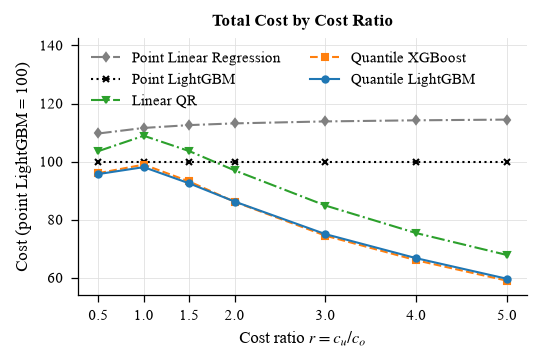

In [12]:
styles = {
    'Point Linear Regression': dict(color='grey', linestyle='-.', marker='d'),
    'Point LightGBM': dict(color='black', linestyle=':', marker='x'),
    'Linear QR': dict(color='tab:green', linestyle='-.', marker='v'),
    'Quantile XGBoost': dict(color='tab:orange', linestyle='--', marker='s'),
    'Quantile LightGBM': dict(color='tab:blue', linestyle='-', marker='o'),
}

fig, ax = plt.subplots(figsize=(ONE_COL, 2.3))
for policy in policies:
    ax.plot(relative_cost.index, relative_cost[policy], markersize=3, label=policy, **styles[policy])
ax.set_title('Total Cost by Cost Ratio')
ax.set_xlabel(r'Cost ratio $r = c_u / c_o$')
ax.set_ylabel('Cost (point LightGBM = 100)')
ax.set_xticks(COST_RATIOS)
ax.set_ylim(relative_cost.values.min() - 5, relative_cost.values.max() + 28)
ax.legend(ncol=2, loc='upper left')
save_fig(fig, 'fig29_cost_by_ratio')
plt.show()

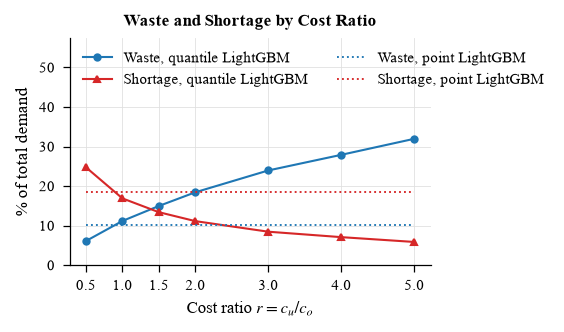

In [13]:
waste = sim_mean['Waste %'].unstack()
shortage = sim_mean['Shortage %'].unstack()

fig, ax = plt.subplots(figsize=(ONE_COL, 2.1))
ax.plot(waste.index, waste['Quantile LightGBM'], color='tab:blue', marker='o', markersize=3, label='Waste, quantile LightGBM')
ax.plot(shortage.index, shortage['Quantile LightGBM'], color='tab:red', marker='^', markersize=3, label='Shortage, quantile LightGBM')
ax.plot(waste.index, waste['Point LightGBM'], color='tab:blue', linestyle=':', linewidth=0.9, label='Waste, point LightGBM')
ax.plot(shortage.index, shortage['Point LightGBM'], color='tab:red', linestyle=':', linewidth=0.9, label='Shortage, point LightGBM')
ax.set_title('Waste and Shortage by Cost Ratio')
ax.set_xlabel(r'Cost ratio $r = c_u / c_o$')
ax.set_ylabel('% of total demand')
ax.set_xticks(COST_RATIOS)
ax.set_ylim(0, max(waste.values.max(), shortage.values.max()) * 1.45)
ax.legend(ncol=2, loc='upper left')
save_fig(fig, 'fig30_waste_shortage_by_ratio')
plt.show()

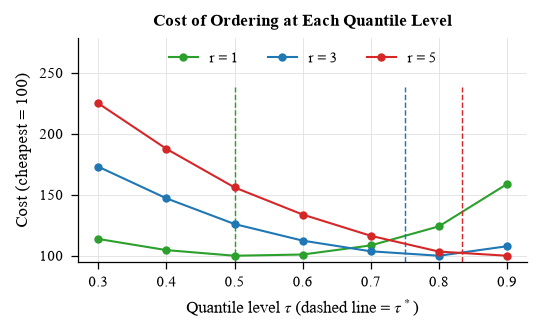

In [14]:
fig, ax = plt.subplots(figsize=(ONE_COL, 2.1))
for r, color in [(1, 'tab:green'), (3, 'tab:blue'), (5, 'tab:red')]:
    curve = cost_curve[r] / cost_curve[r].min() * 100
    ax.plot(curve.index, curve.values, color=color, marker='o', markersize=3, label=f'r = {r}')
    ax.axvline(critical_ratio(r), ymax=0.78, color=color, linestyle='--', linewidth=0.7)
ax.set_title(r'Cost of Ordering at Each Quantile Level')
ax.set_xlabel(r'Quantile level $\tau$ (dashed line = $\tau^*$)')
ax.set_ylabel('Cost (cheapest = 100)')
ax.set_xticks(TAUS)
ax.set_ylim(95, cost_curve.div(cost_curve.min()).values.max() * 100 * 1.22)
ax.legend(loc='upper center', ncol=3)
save_fig(fig, 'fig31_cost_by_tau')
plt.show()

## 4. Save

In [15]:
sim.to_csv('../results/tables/07_simulation_per_fold.csv', index=False)
sim_mean.round(3).to_csv('../results/tables/07_simulation_mean.csv')
relative_cost.round(2).to_csv('../results/tables/07_relative_cost.csv')
cost_curve.round(1).to_csv('../results/tables/07_cost_by_tau.csv')
dm_table.to_csv('../results/tables/07_diebold_mariano.csv', index=False)
print('saved')

saved


## Summary

Cost of each policy compared with ordering the point LightGBM forecast (= 100), mean of 3 folds:

| Cost ratio r | $\tau^*$ | Point Linear Regression | Linear QR | Quantile XGBoost | **Quantile LightGBM** | Saving of quantile LightGBM |
|---|---|---|---|---|---|---|
| 0.5 | 0.33 | 109.7 | 103.6 | 96.0 | 95.7 | 4.3% |
| 1 | 0.50 | 111.6 | 108.9 | 99.0 | 98.1 | 1.9% |
| 1.5 | 0.60 | 112.6 | 103.6 | 93.2 | 92.5 | 7.5% |
| 2 | 0.67 | 113.2 | 97.0 | 86.2 | 86.2 | 13.8% |
| 3 | 0.75 | 113.8 | 84.9 | 74.5 | 75.0 | 25.0% |
| 4 | 0.80 | 114.2 | 75.4 | 66.0 | 66.7 | 33.3% |
| 5 | 0.83 | 114.5 | 67.8 | 59.0 | 59.6 | 40.4% |

**RQ3 answer: yes.** Ordering the quantile forecast at $\tau^*$ is cheaper than ordering the point forecast at
every cost ratio, and the saving grows as shortages get more expensive (2-4% when waste and shortage cost about
the same, 25% at r = 3, 40% at r = 5). Diebold-Mariano on the weekly cost: significant at every r (p < 0.001).

- **Why:** the point forecast is the same whatever the costs are, and it is biased low (more shortage than waste).
  The quantile order moves with the cost ratio: at r = 3 waste goes up from 10.1% to 24.0% of demand, but shortage
  goes down from 18.6% to 8.5%, and the share of weeks with no shortage goes up from 46% to 73%.
- **It is a trade-off, not free.** For high r the kitchen wastes more food to avoid running out. The right r is a
  business decision (cost of the ingredients vs lost sale and unhappy customers), which is why the app lets the
  planner choose it.
- **Model ranking:** quantile XGBoost and LightGBM are within 1 point of each other. Linear QR is only cheaper than the
  point LightGBM forecast from r = 2, and the point Linear Regression is always 10-15% more expensive.
- **The newsvendor rule works on this data:** the cheapest $\tau$ is $\tau^*$ or the next level above it
  (e.g. 0.8 for $\tau^*$ = 0.75). The step up comes from the small under-coverage of the tree models at high levels
  (notebook 06), so a calibration step could give a small extra saving.
- Costs are in "units of wasted portions" ($c_o$ = 1), not money, because the dataset has no cost data.

Saved: `results/tables/07_simulation_per_fold.csv`, `07_simulation_mean.csv`, `07_relative_cost.csv`,
`07_cost_by_tau.csv`, `07_diebold_mariano.csv`.